# EmPath — individual map images
Run All with Python (EmPath). Exports ten PNGs for your document without tile/API requests. Weather is regional context, not a block-level heat measurement.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'scripts').exists(): ROOT = ROOT.parent
assert (ROOT / 'scripts').exists(), 'Open this notebook from the EmPath project.'
sys.path.insert(0, str(ROOT / 'scripts'))

In [2]:
from export_document_layers import export_all
records = export_all()
print(f"Saved {len(records)} images in {ROOT / 'output/document_layers'}")

Saved 10 images in /Users/nalinikantheti/Documents/ChatGPT/EmPath/output/document_layers


**01_four_zip_scope.png** — Source: Census ZCTA polygons. ZIP areas approximate postal geography; all four remain in the pilot.

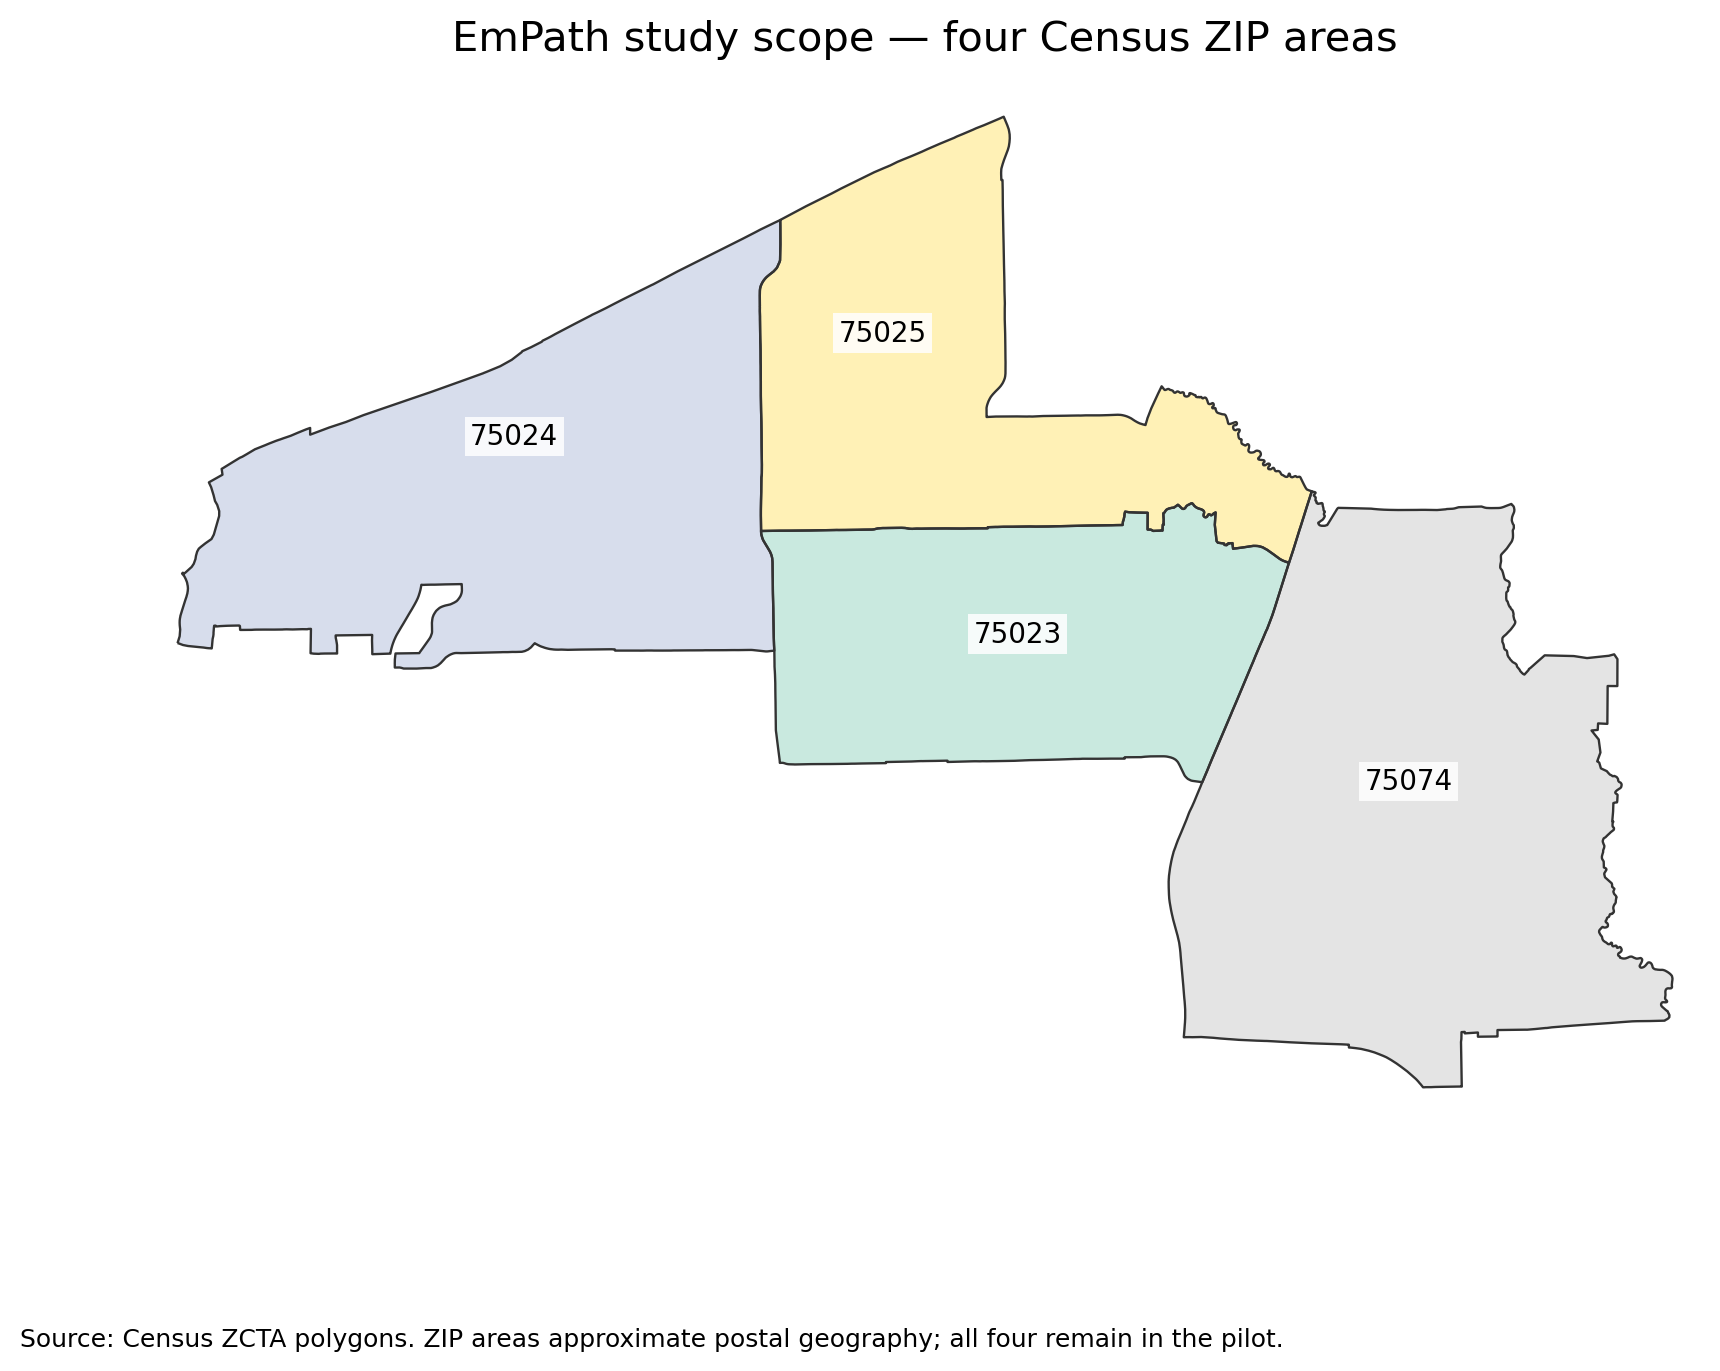

**02_census_blocks.png** — Source: 2020 Census blocks. Polygons are clipped to the pilot; they are not automatically residential clusters.

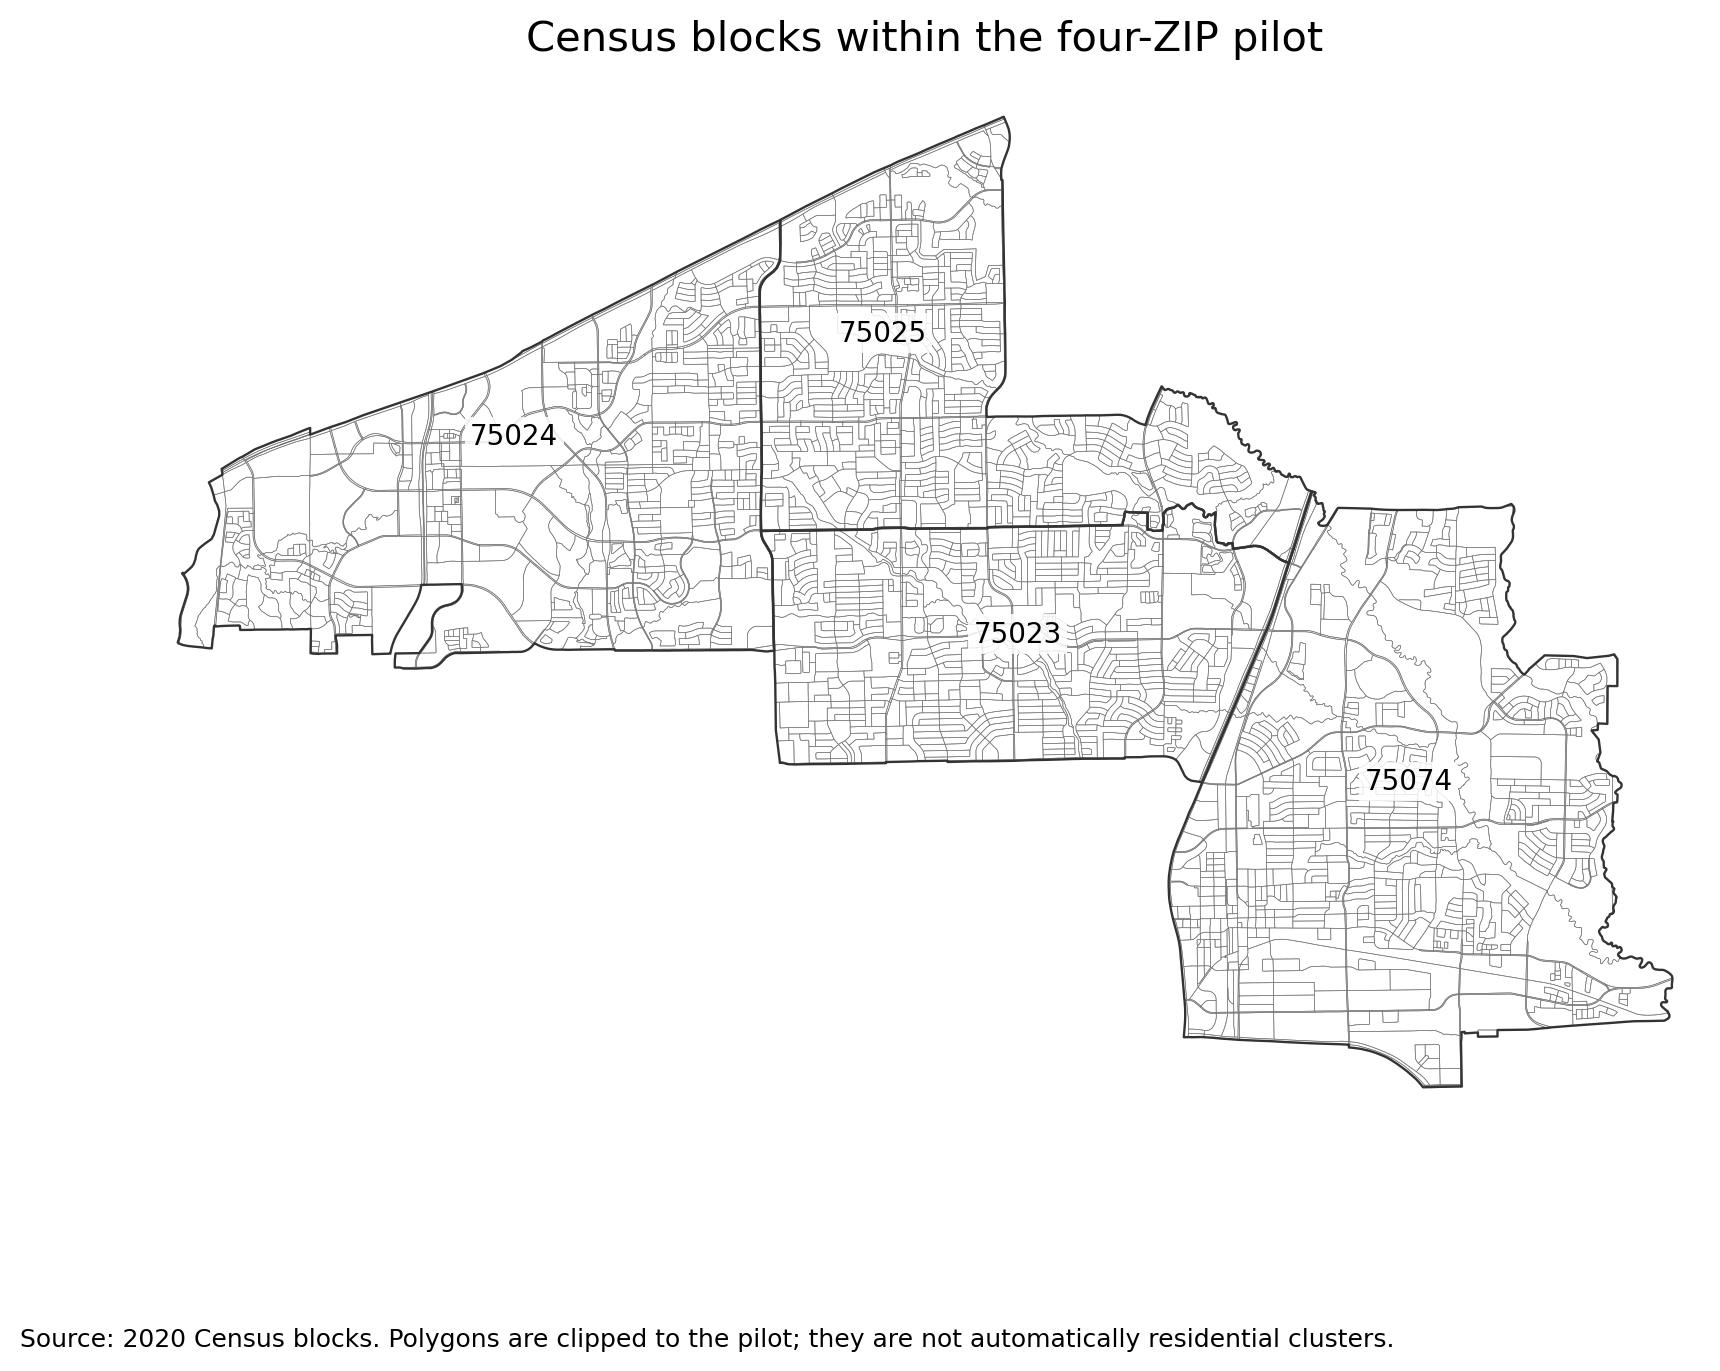

**03_canopy_cover.png** — Texas 2021 canopy classes converted to midpoint estimates; pixel-center block means. Gray = missing. Cover is not time-specific shade.

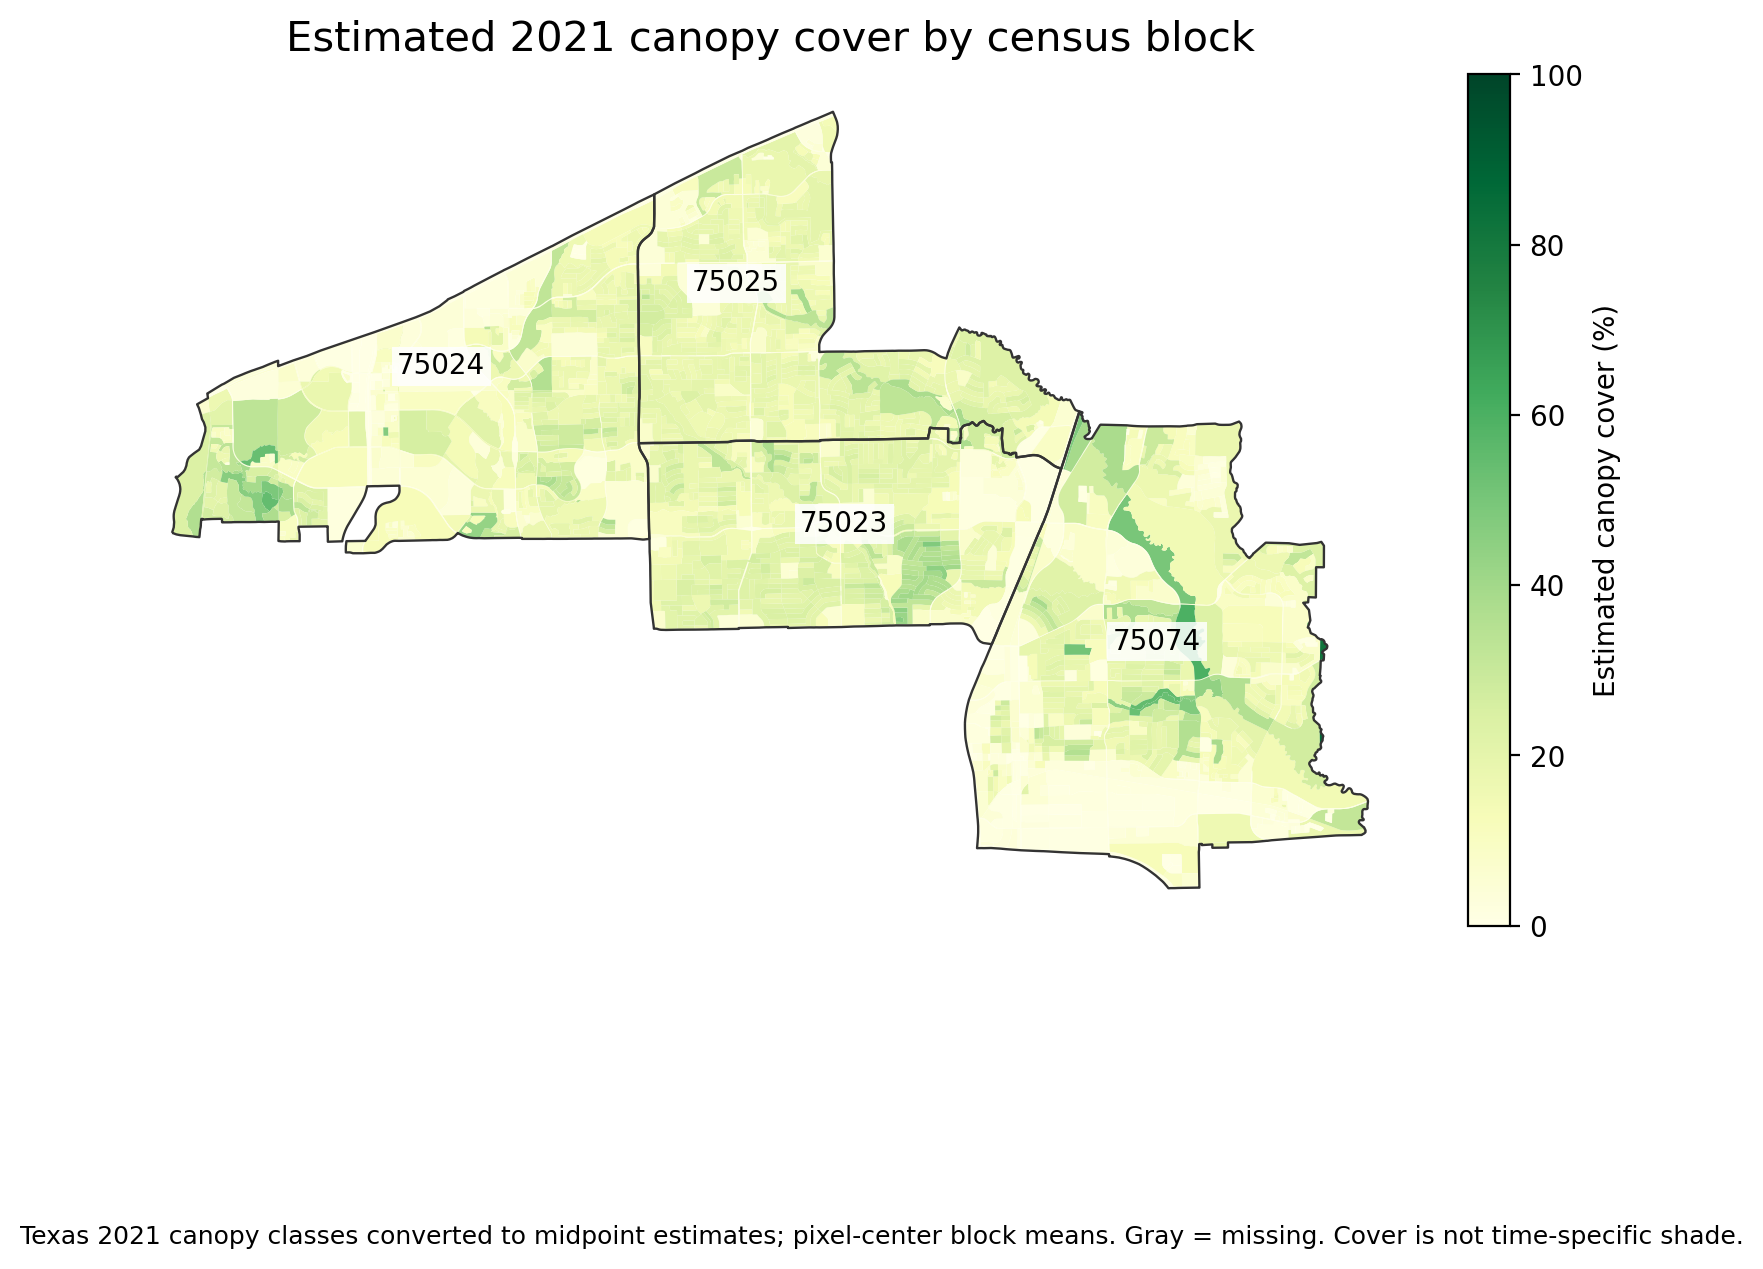

**04_normalized_traffic.png** — Length-weighted mean AADT within block + 100 m; log z-score referenced to 4,387 valid Plano city blocks. Darker = more traffic; not measured danger.

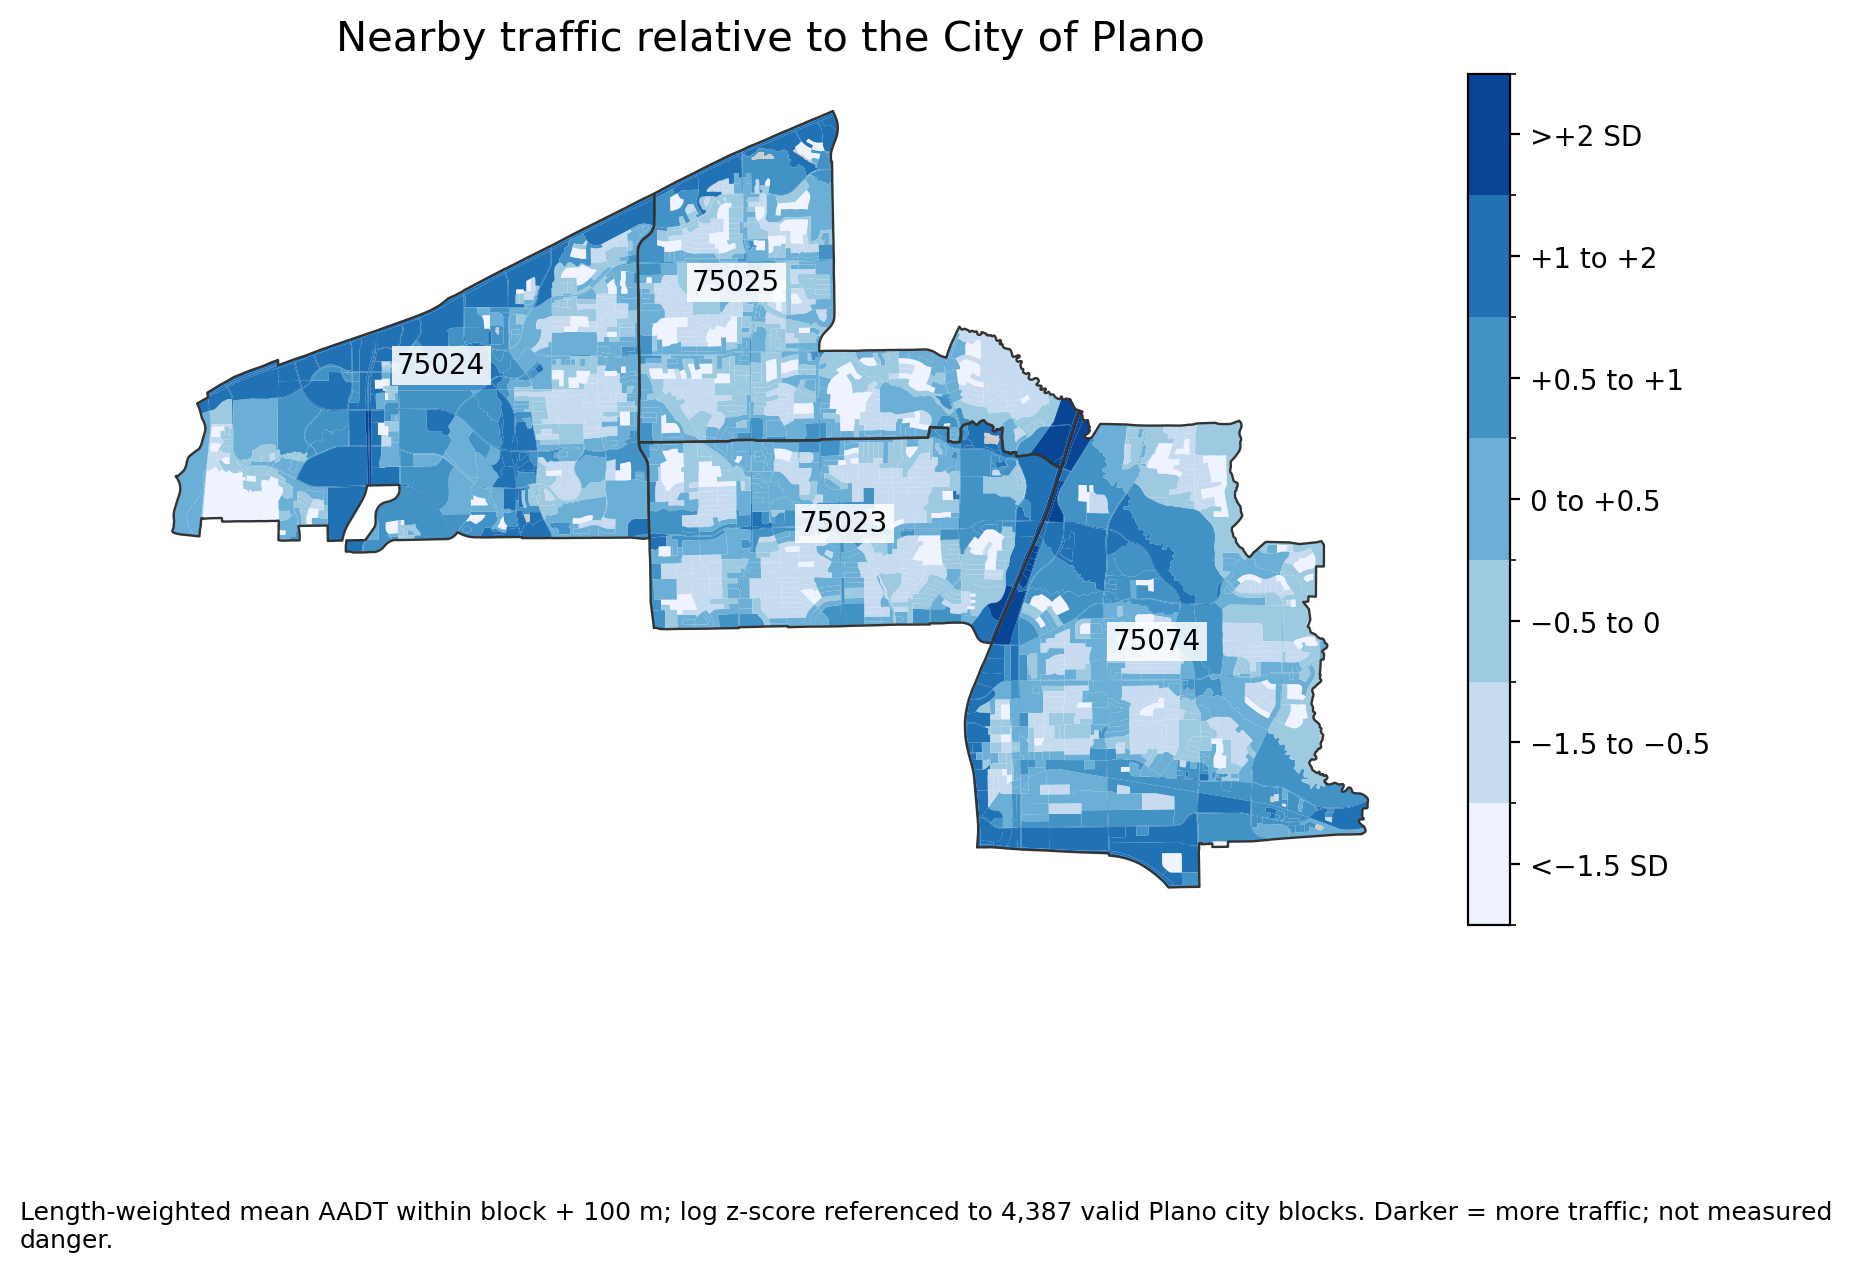

**05_road_traffic_counts.png** — Source: TxDOT AADT inventory extract. Values describe road sections, not total block traffic. Count year is unavailable in this service schema.

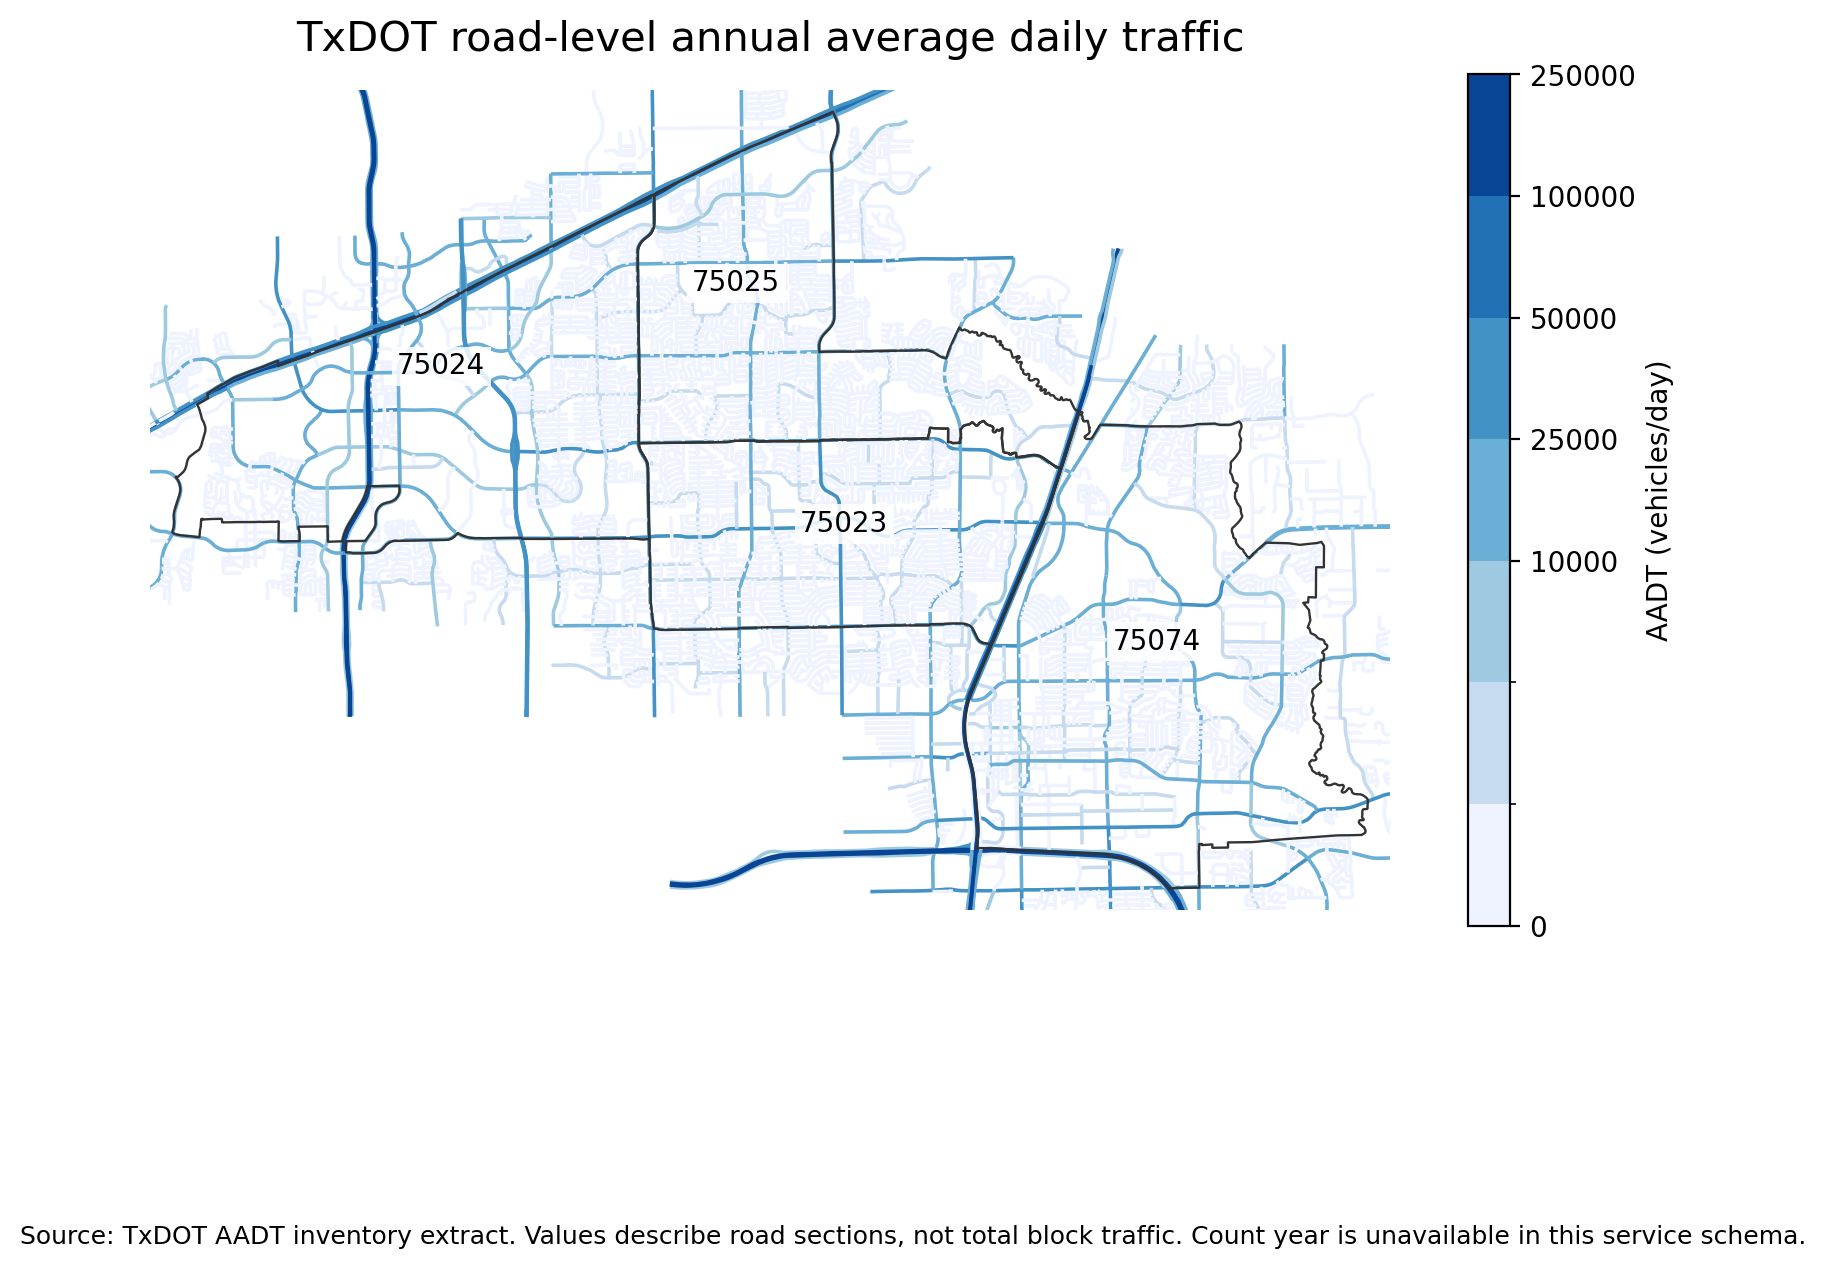

**06_walking_network.png** — Source: OpenStreetMap/OSMnx. Reciprocal geometry is drawn once; graph directions and disconnected components are retained. Access/crossings remain unvalidated.

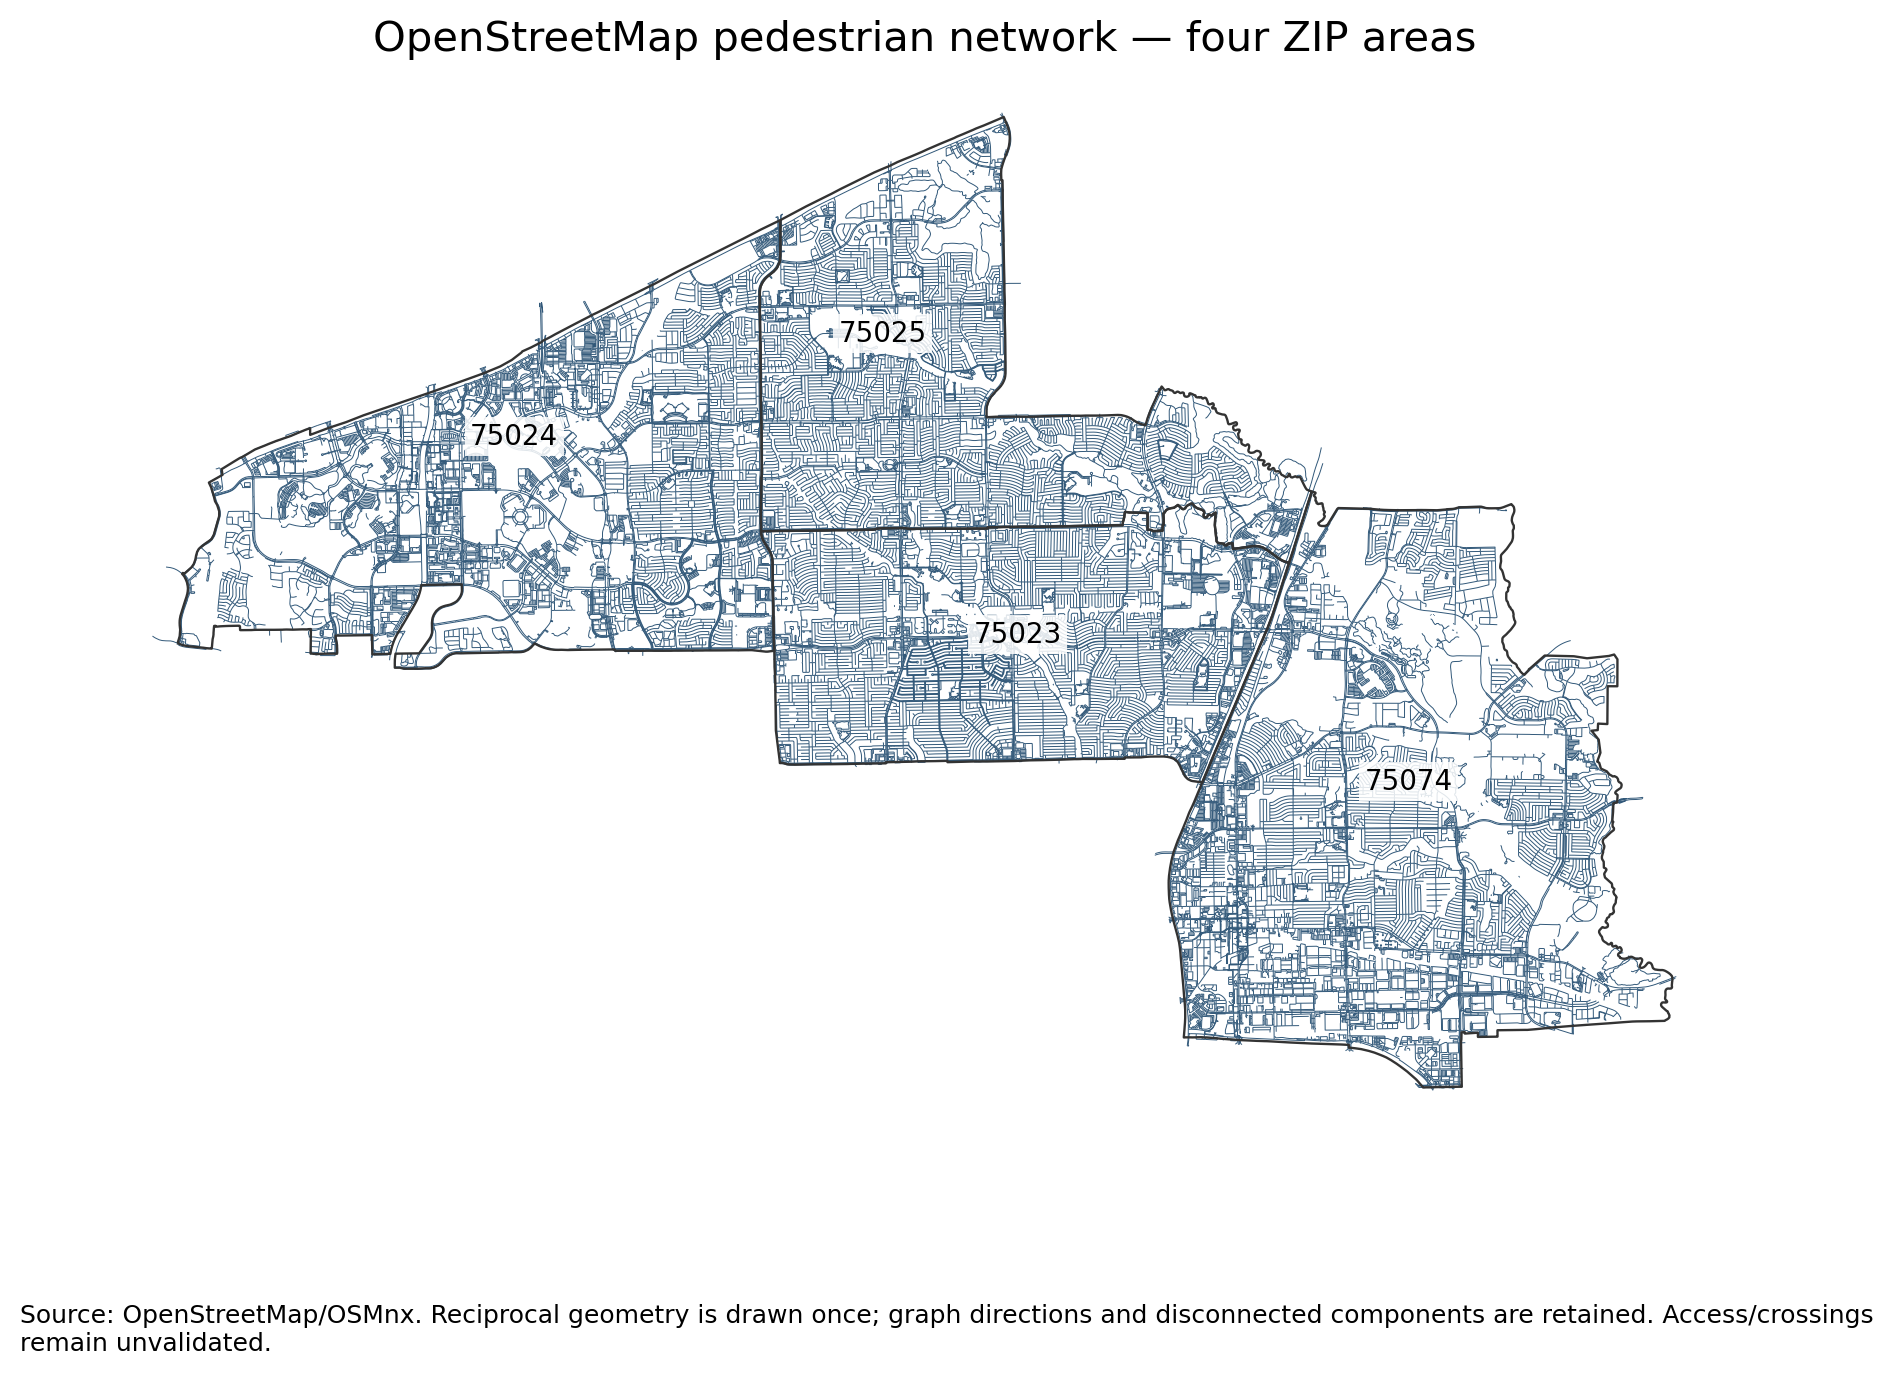

**07_plano_reference_boundary.png** — Official City of Plano municipal polygon defines the traffic reference. Displayed pilot ZIP areas are a different geography.

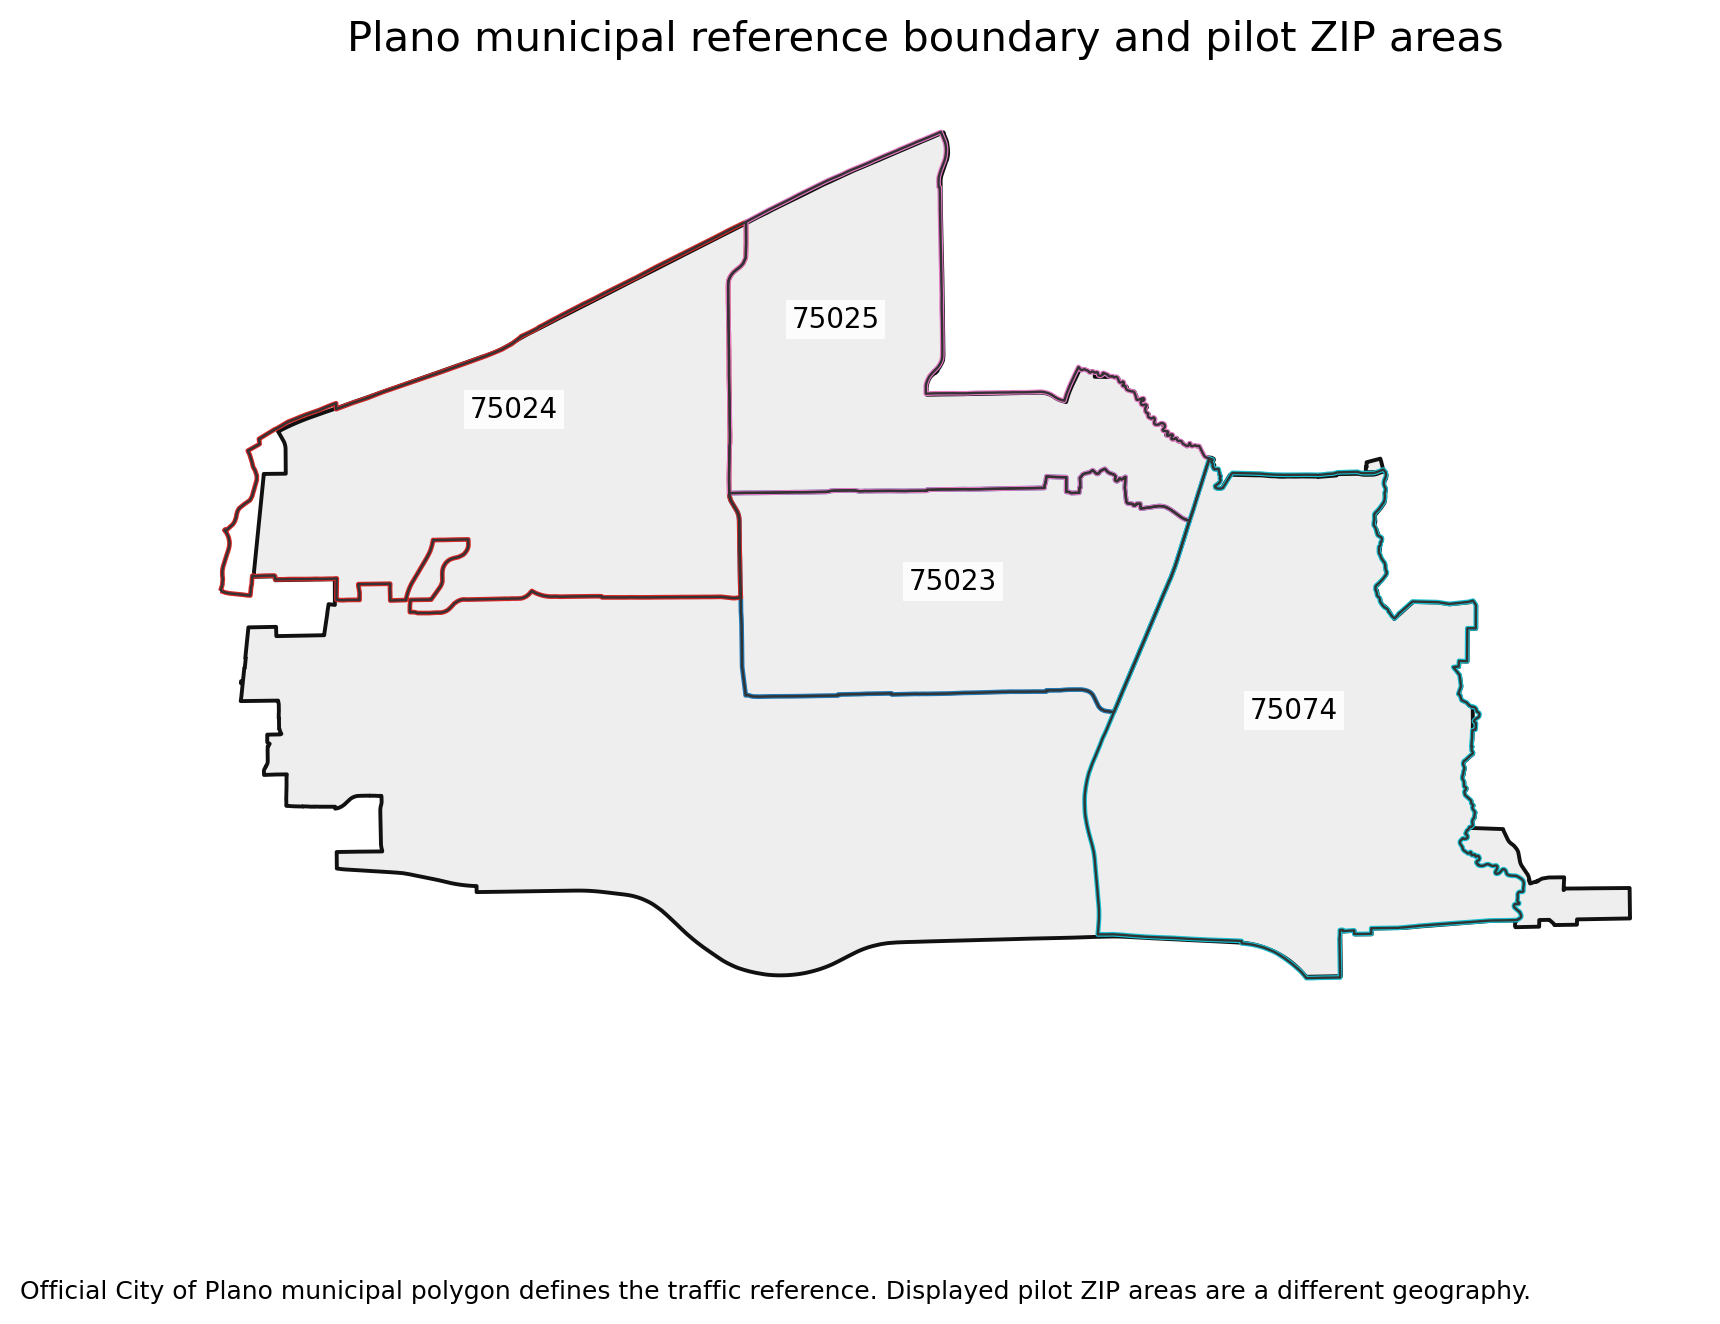

**08_network_and_pois.png** — POIs are OSM feature locations, not verified entrances. Inventory includes 317 selected POIs; temples are not yet included. Convenience shops are not necessarily full grocery stores.

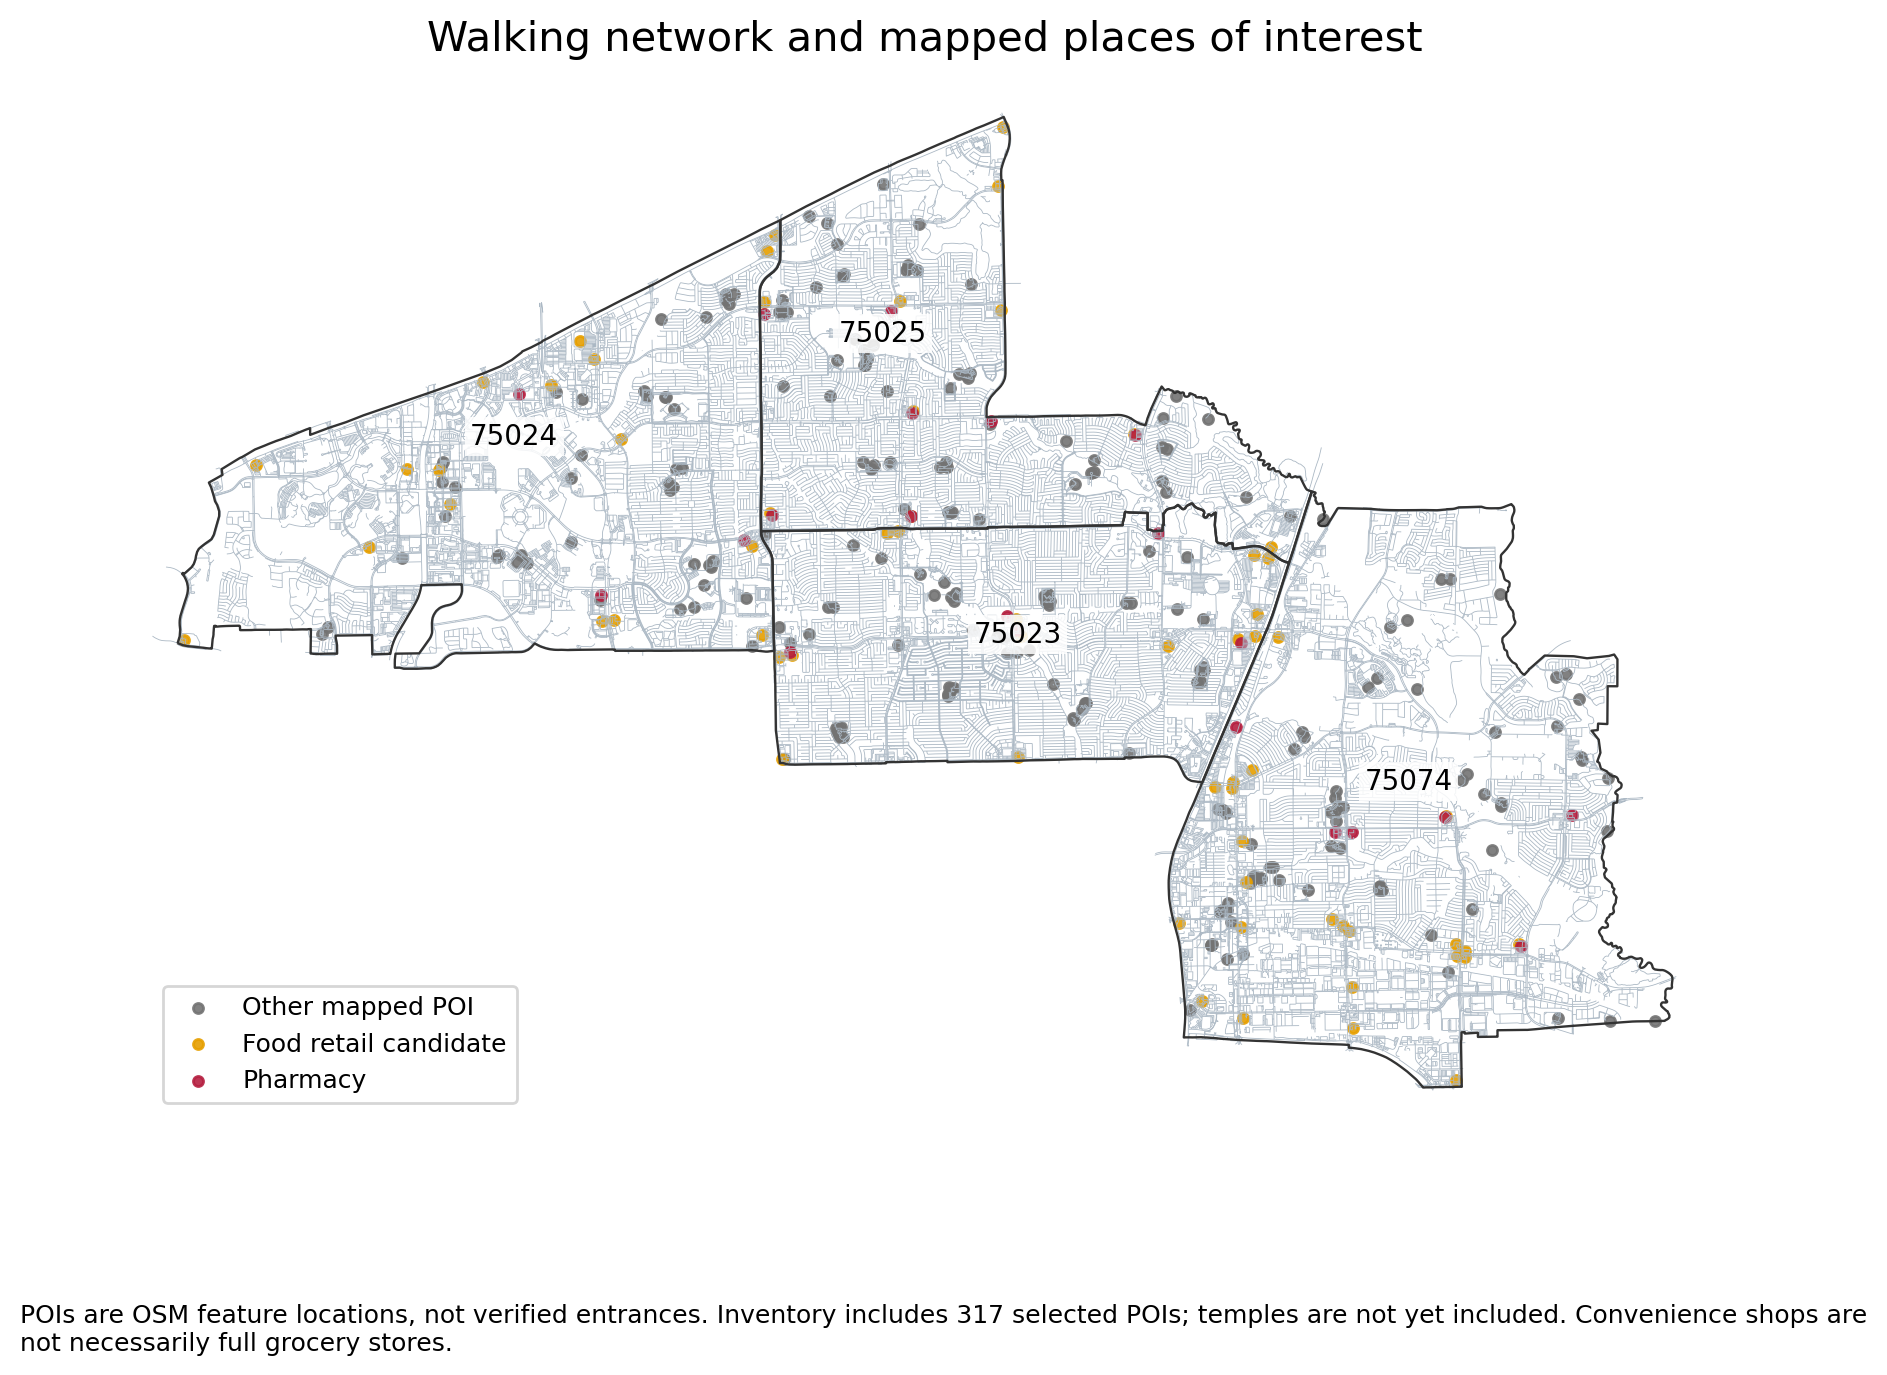

**09_block_address_detail.png** — Example of the interactive close-zoom labels. An address represents one mapped point inside a block; it is not the address of the whole block or a verified entrance.

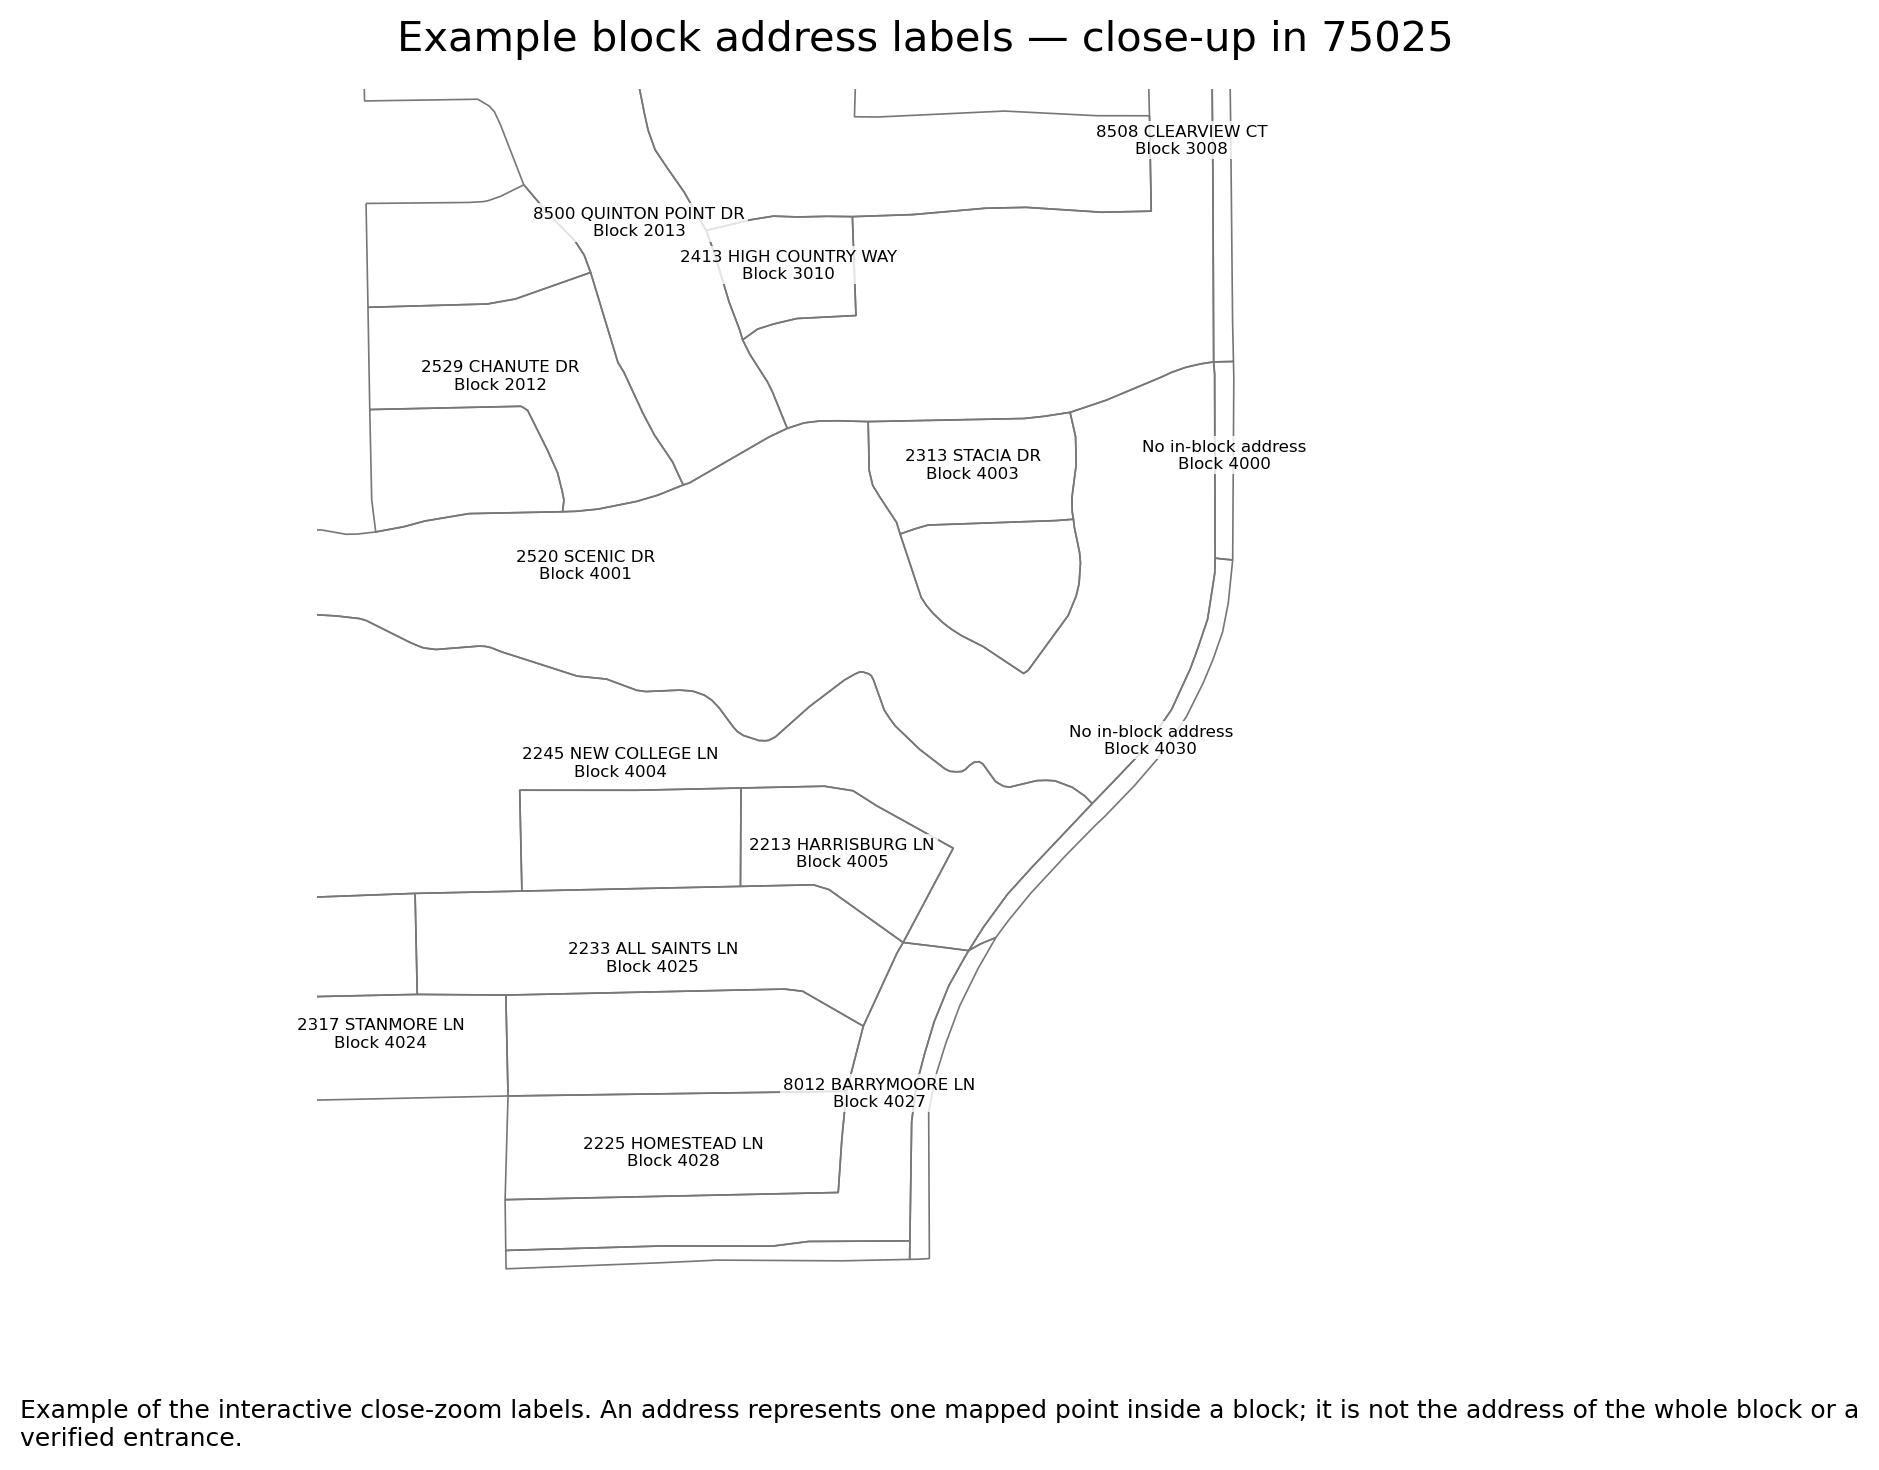

**10_provisional_walking_friction.png** — 50% canopy deficit + 50% traffic; assumed weights. Gray = missing. Not a learned or validated personal comfort score. Regional weather is shared context.

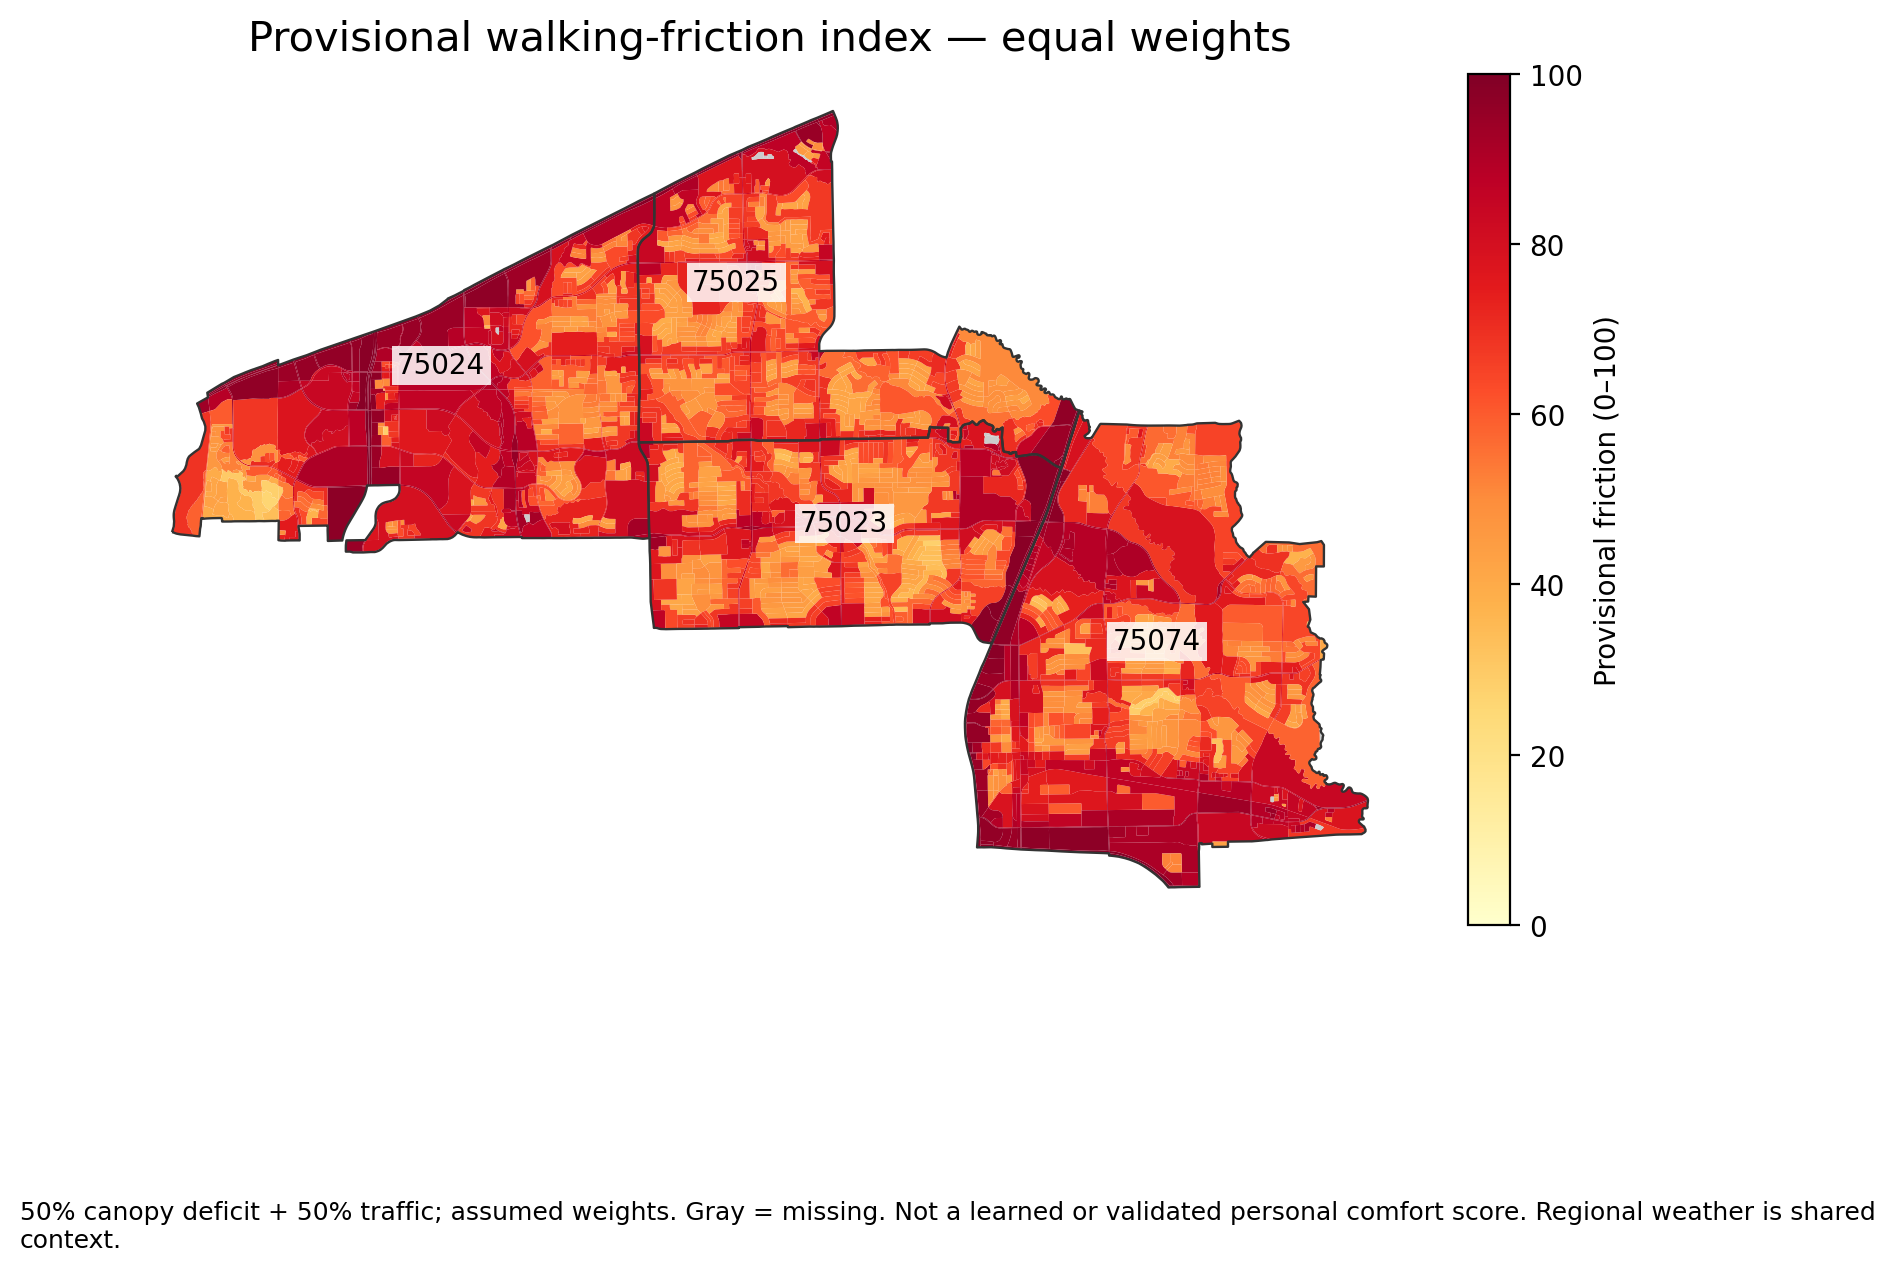

In [3]:
from IPython.display import display, Image, Markdown
for item in records:
    display(Markdown('**' + item['image'] + '** — ' + item['caption']))
    display(Image(filename=str(ROOT / 'output/document_layers' / item['image']), width=800))